In [1]:
import networkx as nx
from BSutils import *
from scipy.stats import unitary_group


[[0 1 1 0 1 0 1 1]
 [1 0 0 1 1 1 1 1]
 [1 0 0 1 1 1 1 1]
 [0 1 1 0 0 1 1 1]
 [1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1]
 [1 1 1 1 0 0 0 0]
 [1 1 1 1 0 1 0 0]]


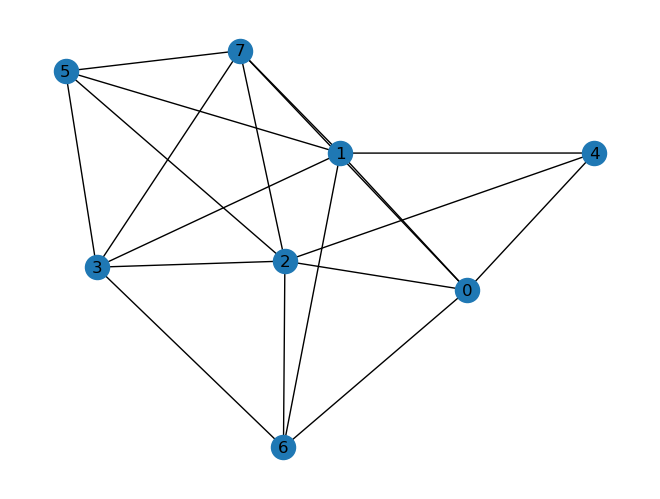

In [2]:
nodes = 8

p = 0.6
G = nx.erdos_renyi_graph(nodes,p=p)


pos = nx.spring_layout(G, seed=42)

adj = nx.adjacency_matrix(G).toarray()

print(adj)



nx.draw( G , with_labels = True,pos=pos) 
plt.show()
# Dstate

In [3]:
unitary,lsv = get_unitary_la(adj)

In [4]:
print(lsv)

4.892241131771936


In [5]:
np.allclose(unitary@unitary.T.conj(),np.eye(2*nodes))

True

In [6]:
subgraph = list(np.random.choice([0,1],size=nodes))

In [7]:
k = sum(subgraph)
subgraph


[1, 1, 1, 1, 1, 1, 1, 0]

In [8]:
# break

In [9]:
# subgraph+[0]*nodes
b = np.array(unitary,dtype=complex)
print(b.shape)
np.abs(expectation_value_permanent(b,subgraph+[0]*nodes))**2

(16, 16)


2.048483644392029e-06

In [10]:
# s_o = [[(0,1),(1,1)]]*nodes+[[(0,1)]]*nodes
state_translator = [ [(i,1)] for i in subgraph]
s_in = state_translator +[[(0,1)]]*nodes
s_o=s_in

sampler = LimOh_sampler(s_in,s_o,b,1000000,verbose=1)
sampler.trust=True


# for _ in range(10):
	# print(np.abs((approx(s_in,s_o,a.T.conj(),size=10000)))**2)

In [11]:
# x = []
# for _ in range(1):
# 	x.append(sampler.approximate(chunk_size=100000))

In [12]:
list(nx.find_cliques(G))

[[1, 0, 4],
 [1, 0, 6],
 [1, 0, 7],
 [1, 3, 5, 7],
 [1, 3, 6],
 [2, 0, 4],
 [2, 0, 6],
 [2, 0, 7],
 [2, 3, 5, 7],
 [2, 3, 6]]

In [13]:
CliffordSampler(unitary,[1,1,1,1]+[0]*16,1000)

AssertionError: Circuit(16) and state(20) size mismatch

In [ ]:
backend = pcvl.Clifford2017Backend()
backend.set_circuit(pcvl.Unitary(pcvl.Matrix(unitary)))
backend.set_input_state(pcvl.BasicState([1,1,1,1]+[0]*16))
	
samples = backend.samples(1_000_000)
print(samples)
samples.count(pcvl.BasicState(pcvl.BasicState([1,1,1,1]+[0]*16)))

[ |0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,0,0,0,0,0>, |0,0,0,0,2,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0>, |0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0>, |0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0>, |1,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0>, |0,0,0,0,0,0,0,1,0,0,0,1,1,1,0,0,0,0,0,0>, |0,0,0,0,2,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0>, |0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,1,0,0,0>, |0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1>, |0,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0>, |0,0,0,0,0,0,0,0,0,0,0,1,2,1,0,0,0,0,0,0>, ... (size=1000000) ]


1

In [ ]:
finder = find_densest_subgraph(G,k,method='sampler',Nsamples=100_000,verbose=0)
print(finder.res_pure)

{'1111111110': 0, '1111111101': 0, '1111111011': 0, '1111110111': 0, '1111101111': 0, '1111011111': 0, '1110111111': 0, '1101111111': 0, '1011111111': 0, '0111111111': 0}


In [ ]:
a = find_maxclique(G,method='exact',verbose=2)
a

10
9
8
7
6
5
4


[[0, 3, 4, 8]]

In [ ]:
res = find_maxclique(G,method='sampler',verbose=2)
res

10
9
8
7
6
5
4


[[0, 3, 4, 8]]

In [ ]:
b = find_maxclique(G,method='approximate',verbose=2)
b

10


100%|██████████| 10/10 [00:05<00:00,  1.76it/s]

9



100%|██████████| 10/10 [00:05<00:00,  1.93it/s]

8



100%|██████████| 10/10 [00:04<00:00,  2.07it/s]

7



100%|██████████| 10/10 [00:05<00:00,  1.89it/s]
Exception ignored in: <Finalize object, dead>
Traceback (most recent call last):
  File "/Users/brian_quandela/Workspace/OQI/.conda/lib/python3.11/multiprocessing/util.py", line 227, in __call__
    res = self._callback(*self._args, **self._kwargs)
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/brian_quandela/Workspace/OQI/.conda/lib/python3.11/multiprocessing/pool.py", line 716, in _terminate_pool
    p.terminate()
  File "/Users/brian_quandela/Workspace/OQI/.conda/lib/python3.11/multiprocessing/process.py", line 133, in terminate
    self._popen.terminate()
  File "/Users/brian_quandela/Workspace/OQI/.conda/lib/python3.11/multiprocessing/popen_fork.py", line 57, in terminate
    self._send_signal(signal.SIGTERM)
  File "/Users/brian_quandela/Workspace/OQI/.conda/lib/python3.11/multiprocessing/popen_fork.py", line 49, in _send_signal
    os.kill(self.pid, sig)
KeyboardInterrupt: 
  0%|          | 0/10 [00:00<?, ?it

[[1, 2, 20, 4],
 [1, 2, 20, 12],
 [1, 2, 20, 6],
 [1, 2, 22, 4],
 [1, 2, 22, 12],
 [1, 3, 20, 12],
 [1, 3, 20, 4],
 [1, 3, 20, 5, 19, 6],
 [1, 3, 6, 16, 19],
 [1, 3, 6, 16, 23],
 [1, 3, 6, 5, 23],
 [1, 3, 22, 0, 12],
 [1, 3, 22, 19, 16],
 [1, 3, 22, 19, 5],
 [1, 3, 22, 23, 16, 12],
 [1, 3, 22, 23, 4],
 [1, 3, 22, 23, 5],
 [1, 14, 20, 5, 6],
 [1, 14, 20, 12],
 [1, 14, 20, 4],
 [1, 14, 21, 4],
 [1, 14, 21, 6],
 [1, 14, 22, 5],
 [1, 14, 22, 12],
 [1, 14, 22, 4],
 [1, 15, 16, 23],
 [1, 15, 21],
 [1, 15, 5, 20],
 [1, 15, 5, 23],
 [1, 21, 0],
 [1, 21, 19, 6],
 [4, 3, 8, 20],
 [4, 3, 8, 23],
 [4, 3, 9, 13],
 [4, 3, 9, 22],
 [4, 3, 13, 20],
 [4, 8, 17, 2, 20],
 [4, 8, 17, 23],
 [4, 8, 14, 20],
 [4, 8, 14, 7],
 [4, 11, 21, 14, 7],
 [4, 11, 13, 2, 20],
 [4, 11, 13, 14, 9],
 [4, 11, 13, 14, 20],
 [4, 11, 13, 14, 7],
 [4, 11, 23],
 [4, 17, 9, 13],
 [4, 17, 9, 22],
 [4, 17, 2, 13, 20],
 [4, 17, 2, 22],
 [4, 17, 21],
 [4, 17, 23, 22],
 [4, 22, 9, 14],
 [4, 22, 7, 14],
 [8, 12, 0, 3],
 [8, 12, 0, 7],